# 🎯 Lesson 2: Supervised Learning
**Week 5 · Notebook 2 of 10 · ⏱️ about 100 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Explain** supervised learning and why it needs a *labelled* dataset.
2. **Train** regression models (linear, k-nearest-neighbours, decision tree) and **interpret** a linear model's coefficients.
3. **Train** classification models and read **decision boundaries** and **class probabilities**.
4. **Generate predictions** with `predict` and `predict_proba`.
5. **Implement** a simple classifier (KNN) from scratch, to demystify what `fit`/`predict` really do.

## 🗺️ Roadmap
`Learning with an answer key` → `Regression` → `Classification` → `What makes a good labelled dataset?` → `Prediction` → **Problems**

> 🚧 **A deliberate shortcut.** In this lesson we train models on *all* the data and look at what they learned. That is **not** how you would evaluate a model: it's like grading a student on questions they've already seen. Lesson 4 fixes this properly. For now, we are learning how models *work*, not how good they are.

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

---
# 📖 Part 1: Learning with an answer key

In supervised learning every training example arrives with its **correct answer** (the *label*). The algorithm's job is to find a mapping

$$\hat y = f(x)$$

that reproduces those answers: **and** keeps working on examples whose answers it has never seen.

Think of a student with a workbook that has the solutions printed in the back. They try a problem, check the answer, adjust their method, and repeat. The "answer key" is the supervision.

| Task | Label looks like | Name | Example |
|---|---|---|---|
| Predict a **number** | 312.5 | **Regression** | house price, temperature, exam score |
| Predict a **category** | "spam" | **Classification** | spam filter, disease diagnosis, species |

Both use the same recipe: **labelled data → `fit` → model → `predict` on new data.**

---
# 📖 Part 2: Regression: predicting numbers

## 2.1 One feature: fitting a line

We'll use the housing data (`price_k` = price in thousands of dollars). First question: *how does price relate to area?*

In [2]:
housing = load("housing.csv")

X1 = housing[["area_sqm"]]          # one feature (double brackets -> 2-D table)
y  = housing["price_k"]

line = LinearRegression().fit(X1, y)
print(f"price ≈ {line.intercept_:.1f} + {line.coef_[0]:.2f} × area_sqm   (price in $1000s)")

price ≈ 15.4 + 3.90 × area_sqm   (price in $1000s)


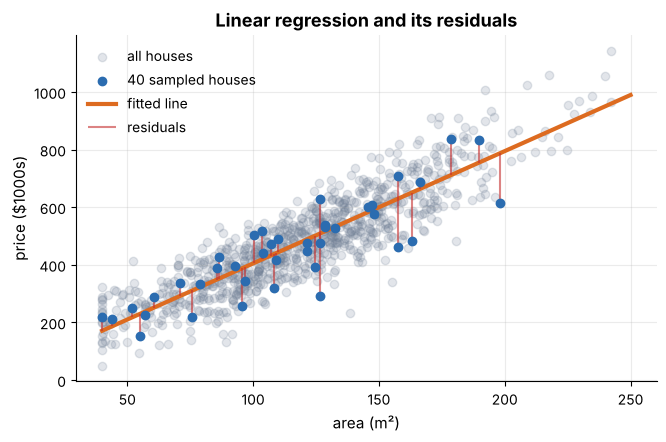

In [3]:
# Visualise the line AND its mistakes ("residuals" = actual − predicted)
sample = housing.sample(40, random_state=1)
pred_sample = line.predict(sample[["area_sqm"]])

plt.scatter(housing["area_sqm"], y, alpha=0.2, color=GREY, label="all houses")
plt.scatter(sample["area_sqm"], sample["price_k"], color=BLUE, zorder=3, label="40 sampled houses")
xs = pd.DataFrame({"area_sqm": np.linspace(40, 250, 50)})
plt.plot(xs["area_sqm"], line.predict(xs), color=ORANGE, lw=3, label="fitted line")
plt.vlines(sample["area_sqm"], sample["price_k"], pred_sample, color=RED, alpha=0.6, label="residuals")
plt.xlabel("area (m²)"); plt.ylabel("price ($1000s)"); plt.title("Linear regression and its residuals")
plt.legend(); plt.show()

**How was this line chosen?** Out of infinitely many possible lines, linear regression picks the one that makes the **sum of squared residuals** as small as possible: the *least-squares* line. (In Lesson 8 you'll build the algorithm that finds it, step by step.)

The model: $\;\hat y = w \cdot x + b\;$: **`w`** is the slope (`coef_`), **`b`** the intercept (`intercept_`). Both are *parameters* (Lesson 1!).

## 2.2 Many features: multiple linear regression

Real prices depend on more than area. Nothing changes conceptually: we just add more terms:

$$\hat y = b + w_1 x_1 + w_2 x_2 + \dots + w_d x_d$$

intercept (b) = -65.4

distance_to_center_km    -4.51
age_years                -1.73
area_sqm                  3.83
bathrooms                11.14
has_garden               23.11
neighborhood_quality     47.51


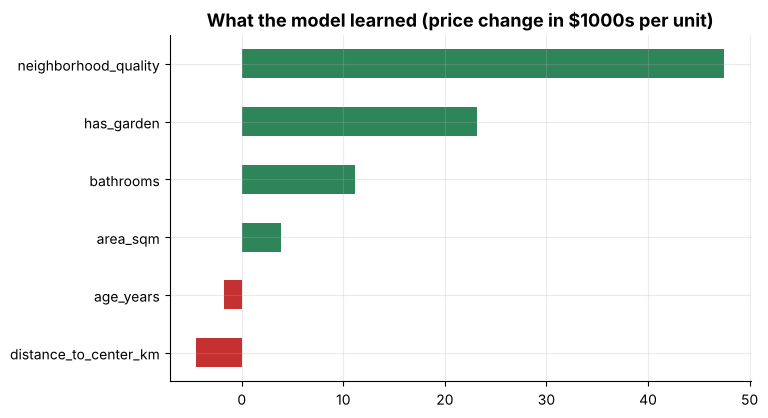

In [4]:
features = ["area_sqm", "bathrooms", "age_years", "distance_to_center_km", "has_garden", "neighborhood_quality"]
X = housing[features]

multi = LinearRegression().fit(X, y)

coefs = pd.Series(multi.coef_, index=features).sort_values()
print(f"intercept (b) = {multi.intercept_:.1f}\n")
print(coefs.round(2).to_string())

coefs.plot.barh(color=[RED if c < 0 else GREEN for c in coefs], title="What the model learned (price change in $1000s per unit)")
plt.show()

### How to *read* these coefficients

Each coefficient says: **"holding all other features fixed, one more unit of this feature changes the predicted price by this much."**

* `age_years` is negative → older houses cost less ✔ (makes sense!).
* `has_garden` is positive → a garden adds value ✔.
* `distance_to_center_km` is negative → further from the centre is cheaper ✔.

Always sanity-check coefficients against common sense. If a coefficient has a surprising sign, investigate: it might reveal a data problem.

> ⚠️ **Caution:** you can't compare coefficients *across features* directly, because they use different units (a unit of `area_sqm` is tiny, a unit of `neighborhood_quality` is huge). Scaling features first (Lesson 3) makes comparison fair.

### 🧑‍🏫 Worked Example 1: A prediction, by hand

Does `model.predict` do anything mysterious? Let's check it with a calculator. Consider this house: **140 m², 2 bathrooms, 10 years old, 5 km from centre, with garden, quality 4.**

I compute **ŷ = b + Σ wᵢ·xᵢ** myself:

In [5]:
house = pd.DataFrame([{"area_sqm": 140, "bathrooms": 2, "age_years": 10,
                       "distance_to_center_km": 5, "has_garden": 1, "neighborhood_quality": 4}])

by_hand = multi.intercept_ + sum(multi.coef_[i] * house.iloc[0, i] for i in range(len(features)))
by_model = multi.predict(house)[0]

print(f"by hand : {by_hand:.2f}")
print(f"predict : {by_model:.2f}")
print(f"→ the model values this house at about ${by_model*1000:,.0f}")

by hand : 665.87
predict : 665.87
→ the model values this house at about $665,867


They're identical. **A linear model's prediction is nothing but a weighted sum.** No magic.

## 2.3 When a straight line isn't enough

Linear models can only draw lines (or flat planes). Two popular alternatives that can bend:

* **K-Nearest Neighbours (KNN):** predict by averaging the labels of the *k* most similar training examples. *"Show me your neighbours and I'll tell you who you are."*
* **Decision tree:** a flowchart of yes/no questions (`area < 110?` → `quality ≥ 4?` → …) that ends in a predicted number.

Let's see how each behaves on a single feature so we can *see* them:

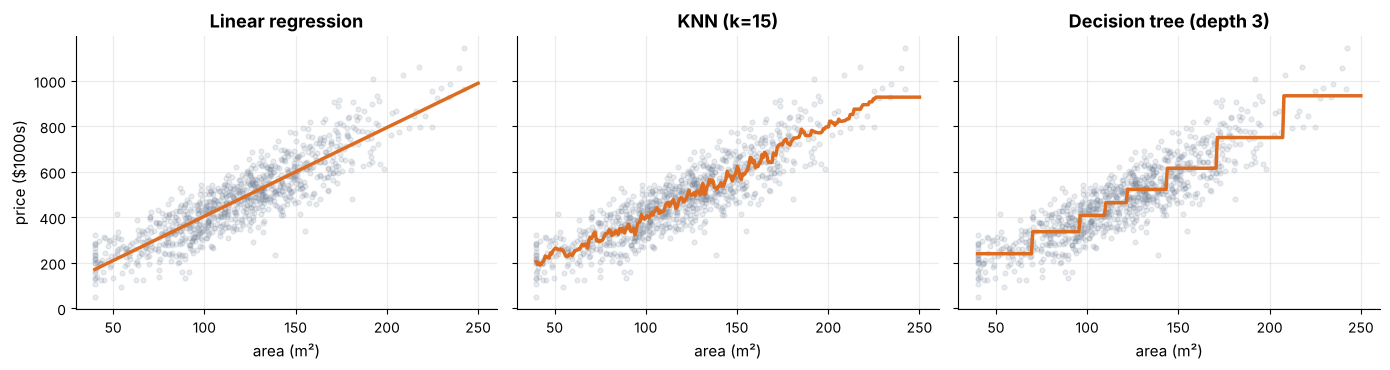

In [6]:
grid = pd.DataFrame({"area_sqm": np.linspace(40, 250, 300)})
models = {
    "Linear regression": LinearRegression(),
    "KNN (k=15)": KNeighborsRegressor(n_neighbors=15),
    "Decision tree (depth 3)": DecisionTreeRegressor(max_depth=3, random_state=0),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, m) in zip(axes, models.items()):
    m.fit(X1, y)
    ax.scatter(housing["area_sqm"], y, alpha=0.15, color=GREY, s=12)
    ax.plot(grid["area_sqm"], m.predict(grid), color=ORANGE, lw=2.5)
    ax.set_title(name); ax.set_xlabel("area (m²)")
axes[0].set_ylabel("price ($1000s)")
plt.tight_layout(); plt.show()

Notice the personalities: the linear model is **rigid but simple**; KNN is **flexible and wiggly**; the tree is **stair-stepped** (it predicts a constant inside each leaf). None is "best" in general: it depends on the data. Choosing among them fairly is the job of Lessons 4–6.

---
# 📖 Part 3: Classification: predicting categories

Classification works like regression, except the answer is a **class label**. We'll use the famous **iris dataset**: 150 flowers, 4 measurements each, 3 species.

In [7]:
iris = load("iris.csv")
print(iris["species"].value_counts().to_string())
iris.head()

species
setosa        50
versicolor    50
virginica     50


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


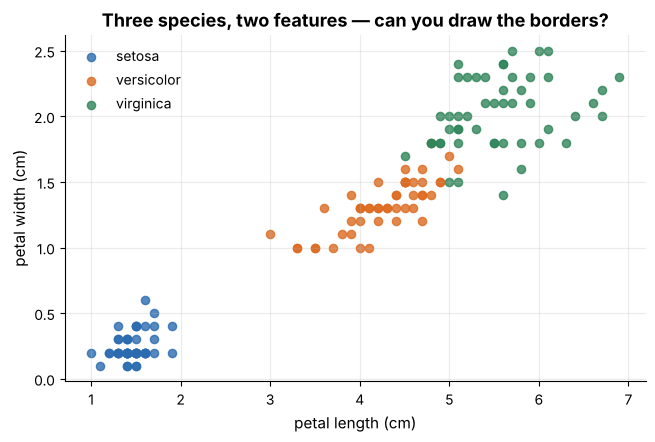

In [8]:
colors = {0: BLUE, 1: ORANGE, 2: GREEN}
names = {0: "setosa", 1: "versicolor", 2: "virginica"}
for k in range(3):
    sub = iris[iris["target"] == k]
    plt.scatter(sub["petal_length_cm"], sub["petal_width_cm"], color=colors[k], label=names[k], s=35, alpha=0.8)
plt.xlabel("petal length (cm)"); plt.ylabel("petal width (cm)")
plt.title("Three species, two features; can you draw the borders?"); plt.legend(); plt.show()

You can almost draw the borders by eye: setosa (blue) is isolated; versicolor and virginica touch. A classifier's job is to draw those borders automatically. The border is called the **decision boundary**. Different algorithms draw very different boundaries:

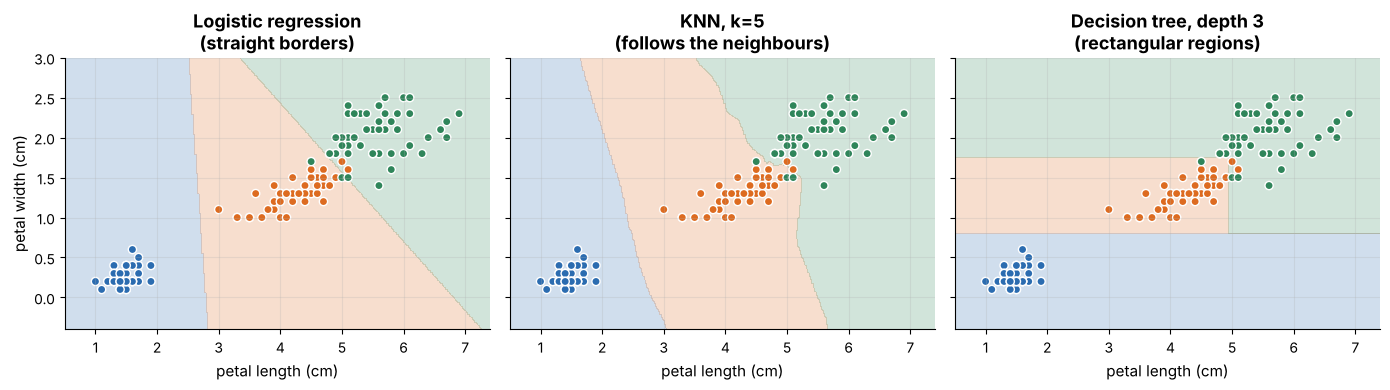

In [9]:
def plot_boundary(model, X2, y_num, ax, title):
    """Fit `model` on two features, then paint the region each class 'owns'."""
    model.fit(X2, y_num)
    x0, x1 = X2[:, 0].min() - .5, X2[:, 0].max() + .5
    y0, y1 = X2[:, 1].min() - .5, X2[:, 1].max() + .5
    xx, yy = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    cmap = ListedColormap([BLUE, ORANGE, GREEN])
    ax.contourf(xx, yy, zz, alpha=0.22, cmap=cmap, levels=[-.5, .5, 1.5, 2.5])
    ax.scatter(X2[:, 0], X2[:, 1], c=y_num, cmap=cmap, edgecolor="white", s=35)
    ax.set_title(title); ax.set_xlabel("petal length (cm)")

X2 = iris[["petal_length_cm", "petal_width_cm"]].to_numpy()
y_num = iris["target"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
plot_boundary(LogisticRegression(max_iter=1000), X2, y_num, axes[0], "Logistic regression\n(straight borders)")
plot_boundary(KNeighborsClassifier(n_neighbors=5), X2, y_num, axes[1], "KNN, k=5\n(follows the neighbours)")
plot_boundary(DecisionTreeClassifier(max_depth=3, random_state=0), X2, y_num, axes[2], "Decision tree, depth 3\n(rectangular regions)")
axes[0].set_ylabel("petal width (cm)")
plt.tight_layout(); plt.show()

Same data, three philosophies:

* **Logistic regression** (despite the name, it's a *classifier*) draws **straight borders**.
* **KNN** draws borders wherever the neighbours disagree: flexible, irregular.
* **Decision trees** slice space into **axis-aligned rectangles**.

### Prediction: labels *and* probabilities

A classifier can answer two questions:

* `predict(x)` → *"which class?"* (a hard decision)
* `predict_proba(x)` → *"how confident are you in each class?"* (a probability per class, summing to 1)

Probabilities are gold: they let you say *"I'm 51% sure"* vs *"I'm 99% sure"*, and they power the ROC curves of Lesson 7.

In [10]:
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
feat_cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]
clf.fit(iris[feat_cols], iris["species"])

flowers = pd.DataFrame([[5.0, 3.4, 1.5, 0.2],      # looks like a setosa
                        [6.0, 2.9, 4.5, 1.5],      # in-between
                        [6.9, 3.1, 5.4, 2.1]],     # looks like a virginica
                       columns=feat_cols)
print("classes:", list(clf.classes_))
print("predict      :", clf.predict(flowers))
print("predict_proba:\n", pd.DataFrame(clf.predict_proba(flowers), columns=clf.classes_).round(3))

classes: ['setosa', 'versicolor', 'virginica']
predict      : ['setosa' 'versicolor' 'virginica']
predict_proba:
    setosa  versicolor  virginica
0   0.981       0.019      0.000
1   0.012       0.779      0.209
2   0.000       0.078      0.922


> 🔧 `make_pipeline(StandardScaler(), model)` chains *standardise the features* → *train the model* into a single object, so you can call `fit` and `predict` on it just like any model. We'll explain **why** scaling matters in Lesson 3. For now treat the pipeline as "a model with a built-in preprocessing step".

The middle flower is a borderline case: its probabilities are spread out. That's useful honesty: the model is telling you *"I'm unsure here."*

### 🧑‍🏫 Worked Example 2: Build a classifier by hand (KNN)

Nothing beats understanding an algorithm by writing it. **KNN classification in three sentences:** (1) measure the distance from the new point to every training point, (2) take the *k* closest, (3) let them vote.

Here is a tiny dataset: fruits described by *weight* (g) and *sweetness* (0–10). Which fruit is a new mystery fruit weighing **150 g with sweetness 6**?

In [11]:
fruit = pd.DataFrame({
    "weight_g":  [120, 126, 140, 161, 172, 100, 110],
    "sweetness": [  3,   4,   5,   7,   8,   9,  10],
    "label":     ["lemon", "lemon", "lemon", "orange", "orange", "grape", "grape"]})
fruit

,weight_g,sweetness,label
0,120,3,lemon
1,126,4,lemon
2,140,5,lemon
3,161,7,orange
4,172,8,orange
5,100,9,grape
6,110,10,grape


In [12]:
mystery = np.array([150, 6])
pts = fruit[["weight_g", "sweetness"]].to_numpy()

# Step 1: distance from the mystery fruit to every fruit (Euclidean distance)
dist = np.sqrt(((pts - mystery) ** 2).sum(axis=1))
fruit["distance"] = dist.round(2)
print(fruit.sort_values("distance").to_string(index=False))

# Step 2 & 3: take the k=3 nearest and vote
k = 3
nearest = fruit.sort_values("distance").head(k)
print(f"\nThe {k} nearest neighbours voted: {list(nearest['label'])}")
print("Majority vote  →", nearest["label"].mode()[0])

 weight_g  sweetness  label  distance
      140          5  lemon     10.05
      161          7 orange     11.05
      172          8 orange     22.09
      126          4  lemon     24.08
      120          3  lemon     30.15
      110         10  grape     40.20
      100          9  grape     50.09

The 3 nearest neighbours voted: ['lemon', 'orange', 'orange']
Majority vote  → orange


Look at the table: the three closest are one *lemon* and two *oranges*, so the vote is **orange**. That is *literally the whole algorithm*. Sklearn's `KNeighborsClassifier` does the same thing, just faster (with clever data structures).

**Try it:** change `k = 3` to `k = 1` and re-run. The nearest *single* fruit is the 140 g lemon, so the answer **flips to lemon**. The hyperparameter *k* changes the prediction: a theme that returns in Lesson 5. And another question to hold on to: what would happen if `weight` were measured in *kilograms* instead of grams? (It's the motivation for feature scaling in Lesson 3.)

---
# 📖 Part 4: What makes a good labelled dataset?

Labels are the fuel of supervised learning, and they are expensive: radiologists' time, human annotators, long waits to see "did the customer eventually leave?". Quality matters more than quantity:

| Property | Why it matters | Failure story |
|---|---|---|
| **Representative** | training data must look like future data | a face detector trained mostly on one demographic fails on others |
| **Correctly labelled** | the model learns the *labels*, mistakes included | 5% mislabelled examples teach the model to be wrong 5% of the time |
| **Enough examples** | too few → the model memorises (Lesson 5) | 30 houses can't reveal a pattern across a city |
| **Balanced enough** | rare classes are easy to ignore | only 15% of customers churn → "always say no" looks 85% accurate |
| **No leakage** | the label must not hide inside the features | a "cancelled_date" column trivially predicts "churned" (Lesson 4) |
| **Features known at prediction time** | otherwise you can't use the model | predicting house prices using the *final sale price per m²* |

---
# 📖 Part 5: The prediction cheat-sheet

| You want… | Call | Returns | Applies to |
|---|---|---|---|
| a number | `model.predict(X)` | array of floats | regression |
| a class label | `model.predict(X)` | array of labels | classification |
| class probabilities | `model.predict_proba(X)` | one column per class | classification |
| learned numbers | `model.coef_`, `model.intercept_` | parameters | linear models |

The whole supervised-learning API in scikit-learn is **`fit` → `predict`**. Learn it once; every model from linear regression to gradient boosting follows the same pattern. 🎉

---
# 🧩 Your turn: Problems

### 🧩 Problem 2.1: Regression or classification? &nbsp; ⭐

Write a function `task_type(series)` that decides whether a target column calls for **`"regression"`** or **`"classification"`**.

Use this simple heuristic:
* text (object/string) column → `"classification"`
* numeric column with **10 or fewer** distinct values → `"classification"`
* otherwise → `"regression"`

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Pandas can tell you `series.dtype` and `series.nunique()`.

</details>

<details>
<summary>💡 Hint 2</summary>

`pd.api.types.is_numeric_dtype(series)` is `True` for numbers.

</details>

In [ ]:
def task_type(series):
    # return "regression" or "classification"
    return None

print(task_type(load("students.csv")["exam_score"]))

In [ ]:
# ✔ Self-check - run this after you have solved the problem
cases = [(load("students.csv")["exam_score"], "regression"),
         (load("churn.csv")["churned"], "classification"),
         (load("iris.csv")["species"], "classification"),
         (load("housing.csv")["price_k"], "regression"),
         (load("wine.csv")["target"], "classification"),
         (load("diabetes.csv")["disease_progression"], "regression")]
for s, expected in cases:
    check(f"{s.name:<22} -> {expected}", lambda: task_type(s) == expected)

### 🧩 Problem 2.2: The price of space &nbsp; ⭐

Using `housing.csv`, fit a **simple linear regression** of `price_k` on `area_sqm` only.

Store the slope (price change in $1000s per extra m²) in a variable called `slope_per_sqm`, and the predicted price of a **100 m²** house in `price_100`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Features must be a 2-D table: `housing[["area_sqm"]]`.

</details>

<details>
<summary>💡 Hint 2</summary>

After `fit`, the slope is `model.coef_[0]`. For a prediction pass `pd.DataFrame({"area_sqm": [100]})`.

</details>

In [ ]:
housing = load("housing.csv")

slope_per_sqm = None
price_100 = None
print(slope_per_sqm, price_100)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("slope is positive and in a sensible range", lambda: 3.0 < slope_per_sqm < 6.5)
check("100 m² house is predicted between 200 and 450 ($1000s)", lambda: 200 < price_100 < 450)

### 🧩 Problem 2.3: Price my house (multiple regression) &nbsp; ⭐⭐

Fit a multiple linear regression on `housing.csv` using these features:
`["area_sqm", "bathrooms", "age_years", "distance_to_center_km", "has_garden", "neighborhood_quality"]`

Store:
* `model`: the fitted model
* `coefs`: a pandas Series of its coefficients indexed by feature name
* `my_house_price`: the predicted price of a house with **area 140, bathrooms 2, age 10, distance 5, garden 1, quality 4**

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`pd.Series(model.coef_, index=features)` gives labelled coefficients.

</details>

<details>
<summary>💡 Hint 2</summary>

Build the one-house table as a DataFrame with the *same columns in the same order*, e.g. `pd.DataFrame([[140, 2, 10, 5, 1, 4]], columns=features)`.

</details>

In [ ]:
housing = load("housing.csv")
features = ["area_sqm", "bathrooms", "age_years", "distance_to_center_km", "has_garden", "neighborhood_quality"]

model = None
coefs = None
my_house_price = None
print(my_house_price)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("age has a negative coefficient (older = cheaper)", lambda: coefs["age_years"] < 0)
check("garden has a positive coefficient", lambda: coefs["has_garden"] > 0)
check("price is plausible (450-900 $1000s)", lambda: 450 < my_house_price < 900)
check("price agrees with model.predict", lambda: abs(my_house_price - model.predict(pd.DataFrame([[140, 2, 10, 5, 1, 4]], columns=features))[0]) < 1e-6)

### 🧩 Problem 2.4: Name that flower (classification) &nbsp; ⭐⭐

Using `iris.csv`, train a `KNeighborsClassifier` with `n_neighbors=5` on **all four measurement columns** (`sepal_length_cm`, `sepal_width_cm`, `petal_length_cm`, `petal_width_cm`) to predict **`species`**.

Predict the species of these two flowers and store the two labels in a list `species_pred`:

| sepal length | sepal width | petal length | petal width |
|---|---|---|---|
| 5.1 | 3.5 | 1.4 | 0.2 |
| 6.7 | 3.0 | 5.2 | 2.3 |

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

The target is the *text* column `species`; sklearn classifiers accept string labels.

</details>

<details>
<summary>💡 Hint 2</summary>

Pass the new flowers as a DataFrame with the same four column names, then convert: `list(model.predict(new))`.

</details>

In [ ]:
iris = load("iris.csv")
feat_cols = ["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]

species_pred = None
print(species_pred)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("two predictions", lambda: len(species_pred) == 2)
check("first flower is a setosa", lambda: species_pred[0] == "setosa")
check("second flower is a virginica", lambda: species_pred[1] == "virginica")

### 🧩 Problem 2.5: How sure is the model? (probabilities) &nbsp; ⭐⭐

Load `breast_cancer.csv`. The target column `target` is **1 = benign, 0 = malignant**; all columns except `target` and `diagnosis` are features.

1. Train `clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))` on all of it.
2. Compute the predicted probability of class **1 (benign)** for every tumour.
3. Find the row whose probability is **closest to 0.5**: the tumour the model is *least sure about*. Store its position in `most_uncertain_idx`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`clf.predict_proba(X)` has two columns: column 0 is P(malignant), column 1 is P(benign).

</details>

<details>
<summary>💡 Hint 2</summary>

Distance from 0.5 is `np.abs(p_benign - 0.5)`; `np.argmin(...)` returns the position of the smallest value.

</details>

In [ ]:
bc = load("breast_cancer.csv")
X = bc.drop(columns=["target", "diagnosis"])
y = bc["target"]

clf = None
most_uncertain_idx = None
print(most_uncertain_idx)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("classifier was trained", lambda: hasattr(clf, "predict_proba"))
check("found the most uncertain row", lambda: most_uncertain_idx == int(np.argmin(np.abs(clf.predict_proba(X)[:, 1] - 0.5))))
check("its probability is close to 0.5 (within 0.1)", lambda: abs(clf.predict_proba(X)[most_uncertain_idx, 1] - 0.5) < 0.1)

### 🧩 Problem 2.6: KNN from scratch &nbsp; ⭐⭐⭐

Implement `knn_predict(X_train, y_train, x_new, k)` **using only NumPy** (no sklearn inside the function):

1. compute the Euclidean distance from `x_new` to every row of `X_train`,
2. find the `k` smallest distances,
3. return the **most common label** among those `k` neighbours.

`X_train` is a 2-D NumPy array, `y_train` a 1-D array of **integer** labels, `x_new` a 1-D array.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Distances: `np.sqrt(((X_train - x_new) ** 2).sum(axis=1))`.

</details>

<details>
<summary>💡 Hint 2</summary>

`np.argsort(dist)[:k]` gives the positions of the `k` nearest rows.

</details>

<details>
<summary>💡 Hint 3</summary>

For a majority vote on integer labels: `np.bincount(labels).argmax()`.

</details>

In [ ]:
def knn_predict(X_train, y_train, x_new, k=5):
    # 1. distances   2. k nearest   3. vote
    return None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
iris = load("iris.csv")
Xa = iris[["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm"]].to_numpy()
ya = iris["target"].to_numpy()
reference = KNeighborsClassifier(n_neighbors=5).fit(Xa, ya)
mine = np.array([knn_predict(Xa, ya, row, k=5) for row in Xa[::5]])
agree = (mine == reference.predict(Xa[::5])).mean()
check(f"agrees with sklearn on {agree:.0%} of 30 flowers (need ≥ 95%)", lambda: agree >= 0.95)

---
## 🎟️ Exit ticket

**Q1.** What makes a problem *supervised*? What's the difference between regression and classification?
**Q2.** A linear regression has `coef_ = [3.9]` for `area_sqm` and `price` in $1000s. In plain English, what does 3.9 mean?
**Q3.** What is the difference between `predict` and `predict_proba`? When would you prefer the latter?
**Q4.** Which algorithm among linear regression, KNN and decision trees can draw *curved or irregular* boundaries without extra tricks?
**Q5.** Why is it a mistake to judge a model by its predictions on the data it was trained on?

<details><summary>👀 Answers</summary>

**A1.** The training data includes the correct answers (labels). Regression predicts numbers; classification predicts categories.
**A2.** Holding everything else fixed, each extra square metre is associated with a $3,900 higher predicted price.
**A3.** `predict` returns the chosen class; `predict_proba` returns a confidence per class. Prefer probabilities when decisions depend on risk, when you want to set your own threshold, or to route uncertain cases to a human.
**A4.** KNN and decision trees (trees give rectangular, step-like regions); plain linear models draw straight/flat boundaries.
**A5.** The model has already seen those answers; a flexible model can just memorise them. We need *unseen* data to measure real performance (Lesson 4).

</details>

---
## 📌 Recap: Lesson 2 on one page

* **Supervised learning** = learn `ŷ = f(x)` from labelled examples. Regression → numbers. Classification → categories.
* **Linear regression:** `ŷ = b + Σ wᵢxᵢ`; coefficients are interpretable ("holding others fixed…"); watch units.
* **KNN** predicts from the *k* nearest examples; **trees** ask a series of yes/no questions; both bend where lines can't.
* **Classifiers** give labels (`predict`) and confidences (`predict_proba`); **decision boundaries** show how each algorithm carves the feature space.
* **Labelled data quality** (representative, correct, enough, balanced, leak-free) matters more than the algorithm.
* We trained on *everything* here on purpose. **Never evaluate on training data**: Lesson 4 shows how to do it right.

**Next up →** `03_unsupervised_learning.ipynb`: what can we learn when there are *no labels at all*?